# 04 · Modelado

**Fase CRISP-DM:** *Modeling* y *Evaluation*. Dada la información de una empresa hoy, ¿tendrá **dificultades financieras** (pérdidas netas o patrimonio negativo) el año siguiente?

- **Entrada:** `data/processed/empresas_limpias.parquet`
- **Salida:** `data/processed/dataset_modelo.parquet` y `figures/fig06_matrices_confusion_test.png`

**Ideas clave:** validación en el tiempo (sin datos del futuro), SMOTE solo en entrenamiento y AUC-ROC como métrica, porque solo ~5 % de las empresas cae en dificultad.

| Conjunto | Año | Uso |
|---|:---:|---|
| Entrenamiento | 2022 | Buscar hiperparámetros |
| Validación | 2023 | Elegir hiperparámetros (AUC) |
| Test | 2024 | Comparar los modelos finales, entrenados con 2022 + 2023 |

2021 queda fuera de los conjuntos porque no tiene año anterior para calcular el crecimiento, y 2025 porque no tiene año siguiente.

| Tipo | Variables | Transformación |
|---|---|---|
| Categóricas | `supervisor`, `department`, `ciiu_division`, `macrosector` | `OneHotEncoder(min_frequency=20)` |
| Financieras | ingresos, ganancia, activos, pasivos, patrimonio | `QuantileTransformer(normal)` + mediana |
| Creadas | `revenue_growth`, `asset_growth`, `current_distress`, `net_margin`, `debt_ratio`, `roa` | Igual, con indicador de nulos |
| **Objetivo** | `next_year_distress` | 1 si el año siguiente hay pérdidas o patrimonio negativo |

Región y ciudad no entran al modelo porque las cubre el departamento.

In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from src import estilo, modelado, utils

torch.manual_seed(42)
optuna.logging.set_verbosity(optuna.logging.WARNING)
estilo.apply_style()

# Intentos de cada búsqueda bayesiana
N_TRIALS = 30
print(modelado.DEVICE)

cuda


## 1. Variable objetivo

In [2]:
df = utils.load_clean()

# Datos del año siguiente: se resta 1 al año para pegarlos a la fila del año actual
next_year = df[["nit", "year", "net_income", "total_equity"]].copy()
next_year["year"] -= 1
next_year.columns = ["nit", "year", "next_net_income", "next_equity"]

# Datos del año anterior: se suma 1 al año
prev_year = df[["nit", "year", "operating_revenue", "total_assets"]].copy()
prev_year["year"] += 1
prev_year.columns = ["nit", "year", "prev_revenue", "prev_assets"]

# Pegar ambos a cada fila (quedan vacíos si la empresa no aparece ese año)
df = df.merge(next_year, on=["nit", "year"], how="left").merge(prev_year, on=["nit", "year"], how="left")

# Quitar los registros sin año siguiente (todo 2025 y las empresas que salen del ranking)
df = df.dropna(subset=["next_net_income"]).reset_index(drop=True)
df["next_year_distress"] = utils.is_distressed(df["next_net_income"], df["next_equity"])

# Proporción (mean) y número (sum) de empresas con dificultades al año siguiente
df.groupby("year")["next_year_distress"].agg(["mean", "sum"]).round(3)

,mean,sum
year,,
2021,0.043,334
2022,0.051,386
2023,0.063,517
2024,0.052,441


## 2. Variables nuevas

In [3]:
# Crecimiento frente al año anterior (0.1 = creció 10 %). Queda vacío si la empresa no estaba
df["revenue_growth"] = df["operating_revenue"] / df["prev_revenue"] - 1
df["asset_growth"] = df["total_assets"] / df["prev_assets"] - 1

# 1 si este año ya tiene pérdidas o patrimonio negativo
df["current_distress"] = utils.is_distressed(df["net_income"], df["total_equity"])

# Indicadores financieros
df["net_margin"] = df["net_income"] / df["operating_revenue"]
df["debt_ratio"] = df["total_liabilities"] / df["total_assets"]
df["roa"] = df["net_income"] / df["total_assets"]

# División CIIU: los 2 primeros dígitos del código
df["ciiu_division"] = df["ciiu"].str[:2]

# Las divisiones por 0 (activos en 0) dan infinito: se dejan vacías
df = df.replace([np.inf, -np.inf], np.nan)

new_cols = ["revenue_growth", "asset_growth", "current_distress", "net_margin", "debt_ratio", "roa"]
df[new_cols].describe().round(2)

,revenue_growth,asset_growth,current_distress,net_margin,debt_ratio,roa
count,21234.00,20746.00,32043.00,32043.00,31237.00,31237.00
mean,0.17,0.14,0.05,0.04,0.56,0.03
std,0.64,0.55,0.21,0.29,0.34,0.14
min,-0.95,-1.00,0.00,-15.00,0.00,-3.00
25%,0.00,0.00,0.00,0.00,0.33,0.00
50%,0.00,0.00,0.00,0.00,0.50,0.00
75%,0.33,0.22,0.00,0.02,0.75,0.03
max,49.00,57.00,1.00,25.00,7.12,13.50


In [4]:
# ¿Las empresas con dificultades hoy las repiten el año siguiente? (proporción por fila)
pd.crosstab(df["current_distress"], df["next_year_distress"], normalize="index").round(3)

next_year_distress,0,1
current_distress,,
0,0.973,0.027
1,0.432,0.568


## 3. Tabla final y exportación

In [5]:
final_cols = [
    "nit", "company_name", "year",
    *utils.CAT_COLS, "ciiu_division",
    *utils.FINANCIAL_COLS, *new_cols,
    "next_year_distress",
]
df_model = df.sort_values(["nit", "year"])[final_cols].reset_index(drop=True)
utils.save(df_model, utils.MODEL_PATH)
df_model.info()

<class 'pandas.DataFrame'>
RangeIndex: 32043 entries, 0 to 32042
Data columns (total 22 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nit                 32043 non-null  str    
 1   company_name        32043 non-null  str    
 2   year                32043 non-null  int64  
 3   supervisor          32043 non-null  str    
 4   region              32043 non-null  str    
 5   department          32043 non-null  str    
 6   city                32043 non-null  str    
 7   ciiu                32043 non-null  str    
 8   macrosector         32043 non-null  str    
 9   ciiu_division       32043 non-null  str    
 10  operating_revenue   32043 non-null  float64
 11  net_income          32043 non-null  float64
 12  total_assets        32043 non-null  float64
 13  total_liabilities   32043 non-null  float64
 14  total_equity        32043 non-null  float64
 15  revenue_growth      21234 non-null  float64
 16  asset_growth   

## 4. Datos para el modelo

In [6]:
model_cat_cols = ["supervisor", "department", "ciiu_division", "macrosector"]
model_num_cols = utils.FINANCIAL_COLS + new_cols

X = df_model[model_cat_cols + model_num_cols]
y = df_model["next_year_distress"].to_numpy()
year = df_model["year"].to_numpy()

is_train = year == 2022
is_val = year == 2023
is_test = year == 2024
# Los modelos finales se entrenan con 2022 y 2023
is_final = is_train | is_val

print("Filas:", is_train.sum(), is_val.sum(), is_test.sum())

Filas: 7518 8229 8503


In [7]:
preprocessor = ColumnTransformer([
    # Categóricas: una columna 0/1 por categoría. Las que tienen menos de 20 empresas se agrupan
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False), model_cat_cols),
    # Numéricas: llevar a distribución normal por cuantiles y rellenar los vacíos con la mediana
    ("num", make_pipeline(
        QuantileTransformer(output_distribution="normal", random_state=42),
        SimpleImputer(strategy="median", add_indicator=True),
    ), model_num_cols),
])

# Se ajusta solo con entrenamiento y se aplica a todas las filas
preprocessor.fit(X[is_train])
X_prep = preprocessor.transform(X)
X_prep.shape

(32043, 101)

## 5. Balanceo con SMOTE

SMOTE toma una empresa con dificultades y una de sus 5 vecinas más parecidas, y crea una empresa nueva en un punto intermedio. Solo se aplica a entrenamiento: validación y test quedan intactos.

In [8]:
smote = SMOTE(random_state=42)
# Cada conjunto es una pareja (X, y)
train_bal = smote.fit_resample(X_prep[is_train], y[is_train])
final_bal = smote.fit_resample(X_prep[is_final], y[is_final])
val = (X_prep[is_val], y[is_val])
X_test, y_test = X_prep[is_test], y[is_test]

# Empresas sin y con dificultades, antes y después
print("Antes:", np.bincount(y[is_final]))
print("Después:", np.bincount(final_bal[1]))

Antes: [14844   903]
Después: [14844 14844]


## 6. Modelos

Cada modelo se entrena con 2022 + 2023 balanceado y da un puntaje de riesgo para cada empresa de test (2024). Los que tienen hiperparámetros los eligen con el AUC de validación (2023).

In [9]:
# Puntaje de riesgo en test de cada modelo
prob_test = {}

### 6.1 Regresión logística y Naive Bayes

In [10]:
prob_test["Regresión logística"] = modelado.fit_and_score(LogisticRegression(max_iter=1000), final_bal, X_test)
prob_test["Naive Bayes"] = modelado.fit_and_score(GaussianNB(), final_bal, X_test, score=modelado.log_odds)

### 6.2 K vecinos más cercanos

In [11]:
def make_knn(k):
    return KNeighborsClassifier(n_neighbors=k, n_jobs=-1)


best_k, auc_by_k = modelado.tune(make_knn, [25, 50, 100, 200, 400], train_bal, val)
print("Mejor k:", best_k)
prob_test["K vecinos"] = modelado.fit_and_score(make_knn(best_k), final_bal, X_test)

Mejor k: 400


### 6.3 SVM

In [12]:
# C bajo = frontera más suave, C alto = frontera más pegada a los datos
def make_svm(c):
    return SVC(kernel="rbf", C=c)


best_c, auc_by_c = modelado.tune(make_svm, [0.1, 1, 10], train_bal, val, score=modelado.margin)
print("Mejor C:", best_c)
prob_test["SVM"] = modelado.fit_and_score(make_svm(best_c), final_bal, X_test, score=modelado.margin)

Mejor C: 0.1


### 6.4 Árbol de decisión

In [13]:
# min_samples_leaf evita hojas con muy pocas empresas
def make_tree(depth):
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=20, random_state=42)


best_depth, auc_by_depth = modelado.tune(make_tree, range(2, 13), train_bal, val)
print("Mejor profundidad:", best_depth)
prob_test["Árbol de decisión"] = modelado.fit_and_score(make_tree(best_depth), final_bal, X_test)

Mejor profundidad: 6


### 6.5 Random forest con grid search

**¿Por qué optimizar?** Los hiperparámetros por defecto no están pensados para datos financieros de colas pesadas, ~5 % de clase positiva y datos sintéticos de SMOTE: un modelo muy flexible sobreajusta y uno muy rígido ignora a las empresas en riesgo. Por eso se eligen con el **AUC de validación (2023)**: *grid search* como referencia, Optuna (búsqueda bayesiana) en un espacio más amplio y, en la red, Optuna también elige el optimizador (**Adam, RMSprop o SGD**) como un hiperparámetro más.

In [14]:
def make_rf(params):
    return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42, **params)


param_grid = {
    # Profundidad máxima de cada árbol (None = sin límite)
    "max_depth": [None, 10, 20],
    # Mínimo de empresas en cada hoja
    "min_samples_leaf": [1, 5, 10, 20],
    # Variables que mira cada división: raíz cuadrada del total o el 30 %
    "max_features": ["sqrt", 0.3],
}

# GridSearchCV con un único corte fijo: entrena con 2022 balanceado y valida con 2023
X_search, y_search, fixed_split = modelado.fixed_validation(train_bal, val)
# refit=False: el modelo final se entrena aparte con 2022 y 2023
grid_search = GridSearchCV(make_rf({}), param_grid, scoring="roc_auc", cv=fixed_split, refit=False)
grid_search.fit(X_search, y_search)
print("Mejores hiperparámetros:", grid_search.best_params_)

prob_test["RF grid search"] = modelado.fit_and_score(make_rf(grid_search.best_params_), final_bal, X_test)

Mejores hiperparámetros: {'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 20}


### 6.6 Random forest con búsqueda bayesiana

In [15]:
def rf_objective(trial):
    # Hiperparámetros que Optuna prueba en cada intento
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        "max_features": trial.suggest_float("max_features", 0.05, 0.6),
    }
    return modelado.validation_auc(make_rf(params), train_bal, val)


rf_study = modelado.run_study(rf_objective, N_TRIALS)
print("Mejores hiperparámetros:", rf_study.best_params)

prob_test["RF bayesiana"] = modelado.fit_and_score(make_rf(rf_study.best_params), final_bal, X_test)

  0%|          | 0/30 [00:00<?, ?it/s]

Mejores hiperparámetros: {'max_depth': 15, 'min_samples_leaf': 19, 'max_features': 0.15982058018709783}


### 6.7 Red neuronal

In [16]:
def net_objective(trial):
    # Hiperparámetros que Optuna prueba en cada intento
    params = {
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "n_neurons": trial.suggest_int("n_neurons", 16, 256, log=True),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
        "epochs": trial.suggest_int("epochs", 5, 50),
        "optimizer": trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"]),
    }
    net = modelado.train_net(params, *train_bal)
    return roc_auc_score(val[1], modelado.predict_net(net, val[0]))


net_study = modelado.run_study(net_objective, N_TRIALS)
print("Mejores hiperparámetros:", net_study.best_params)

net = modelado.train_net(net_study.best_params, *final_bal)
prob_test["Red neuronal"] = modelado.predict_net(net, X_test)

  0%|          | 0/30 [00:00<?, ?it/s]

Mejores hiperparámetros: {'n_layers': 2, 'n_neurons': 21, 'dropout': 0.35036056533830984, 'lr': 0.003155662624116798, 'epochs': 50, 'optimizer': 'SGD'}


## 7. Efecto de la optimización

Cada búsqueda probó varias configuraciones y midió el AUC en validación (2023). La primera tabla compara la peor y la mejor configuración de cada modelo. La segunda muestra el optimizador de la red, uno de los hiperparámetros que buscó Optuna.

In [17]:
val_auc_by_model = {
    "K vecinos": list(auc_by_k.values()),
    "SVM": list(auc_by_c.values()),
    "Árbol de decisión": list(auc_by_depth.values()),
    "RF grid search": list(grid_search.cv_results_["mean_test_score"]),
    "RF bayesiana": rf_study.trials_dataframe()["value"].tolist(),
    "Red neuronal": net_study.trials_dataframe()["value"].tolist(),
}
modelado.tuning_summary(val_auc_by_model).round(3)

,Configuraciones,Peor AUC,Mejor AUC,Ganancia
Red neuronal,30,0.844,0.908,0.063
Árbol de decisión,11,0.837,0.885,0.047
SVM,3,0.850,0.894,0.043
K vecinos,5,0.868,0.897,0.028
RF bayesiana,30,0.898,0.908,0.011
RF grid search,24,0.898,0.908,0.009


In [18]:
# Intentos, mejor AUC y AUC mediana de validación por optimizador
optimizer_comparison = net_study.trials_dataframe().groupby("params_optimizer")["value"].agg(["count", "max", "median"])
optimizer_comparison.columns = ["Intentos", "Mejor AUC", "AUC mediana"]
optimizer_comparison.index.name = "Optimizador"
optimizer_comparison.sort_values("Mejor AUC", ascending=False).round(3)

,Intentos,Mejor AUC,AUC mediana
Optimizador,,,
SGD,21,0.908,0.905
RMSprop,5,0.901,0.857
Adam,4,0.874,0.865


## 8. Comparación en test (2024)

Regla operativa: se marca **en riesgo** al 10 % de empresas con mayor puntaje (`flag_at_risk`).

In [19]:
results = modelado.evaluate(prob_test, y_test)
results.round(3)

,AUC,Accuracy,Precisión,Recall
Red neuronal,0.904,0.918,0.347,0.669
RF grid search,0.901,0.917,0.344,0.662
RF bayesiana,0.901,0.916,0.338,0.651
Regresión logística,0.898,0.918,0.348,0.671
K vecinos,0.891,0.916,0.339,0.653
SVM,0.882,0.917,0.342,0.660
Árbol de decisión,0.881,0.910,0.308,0.594
Naive Bayes,0.810,0.907,0.296,0.571


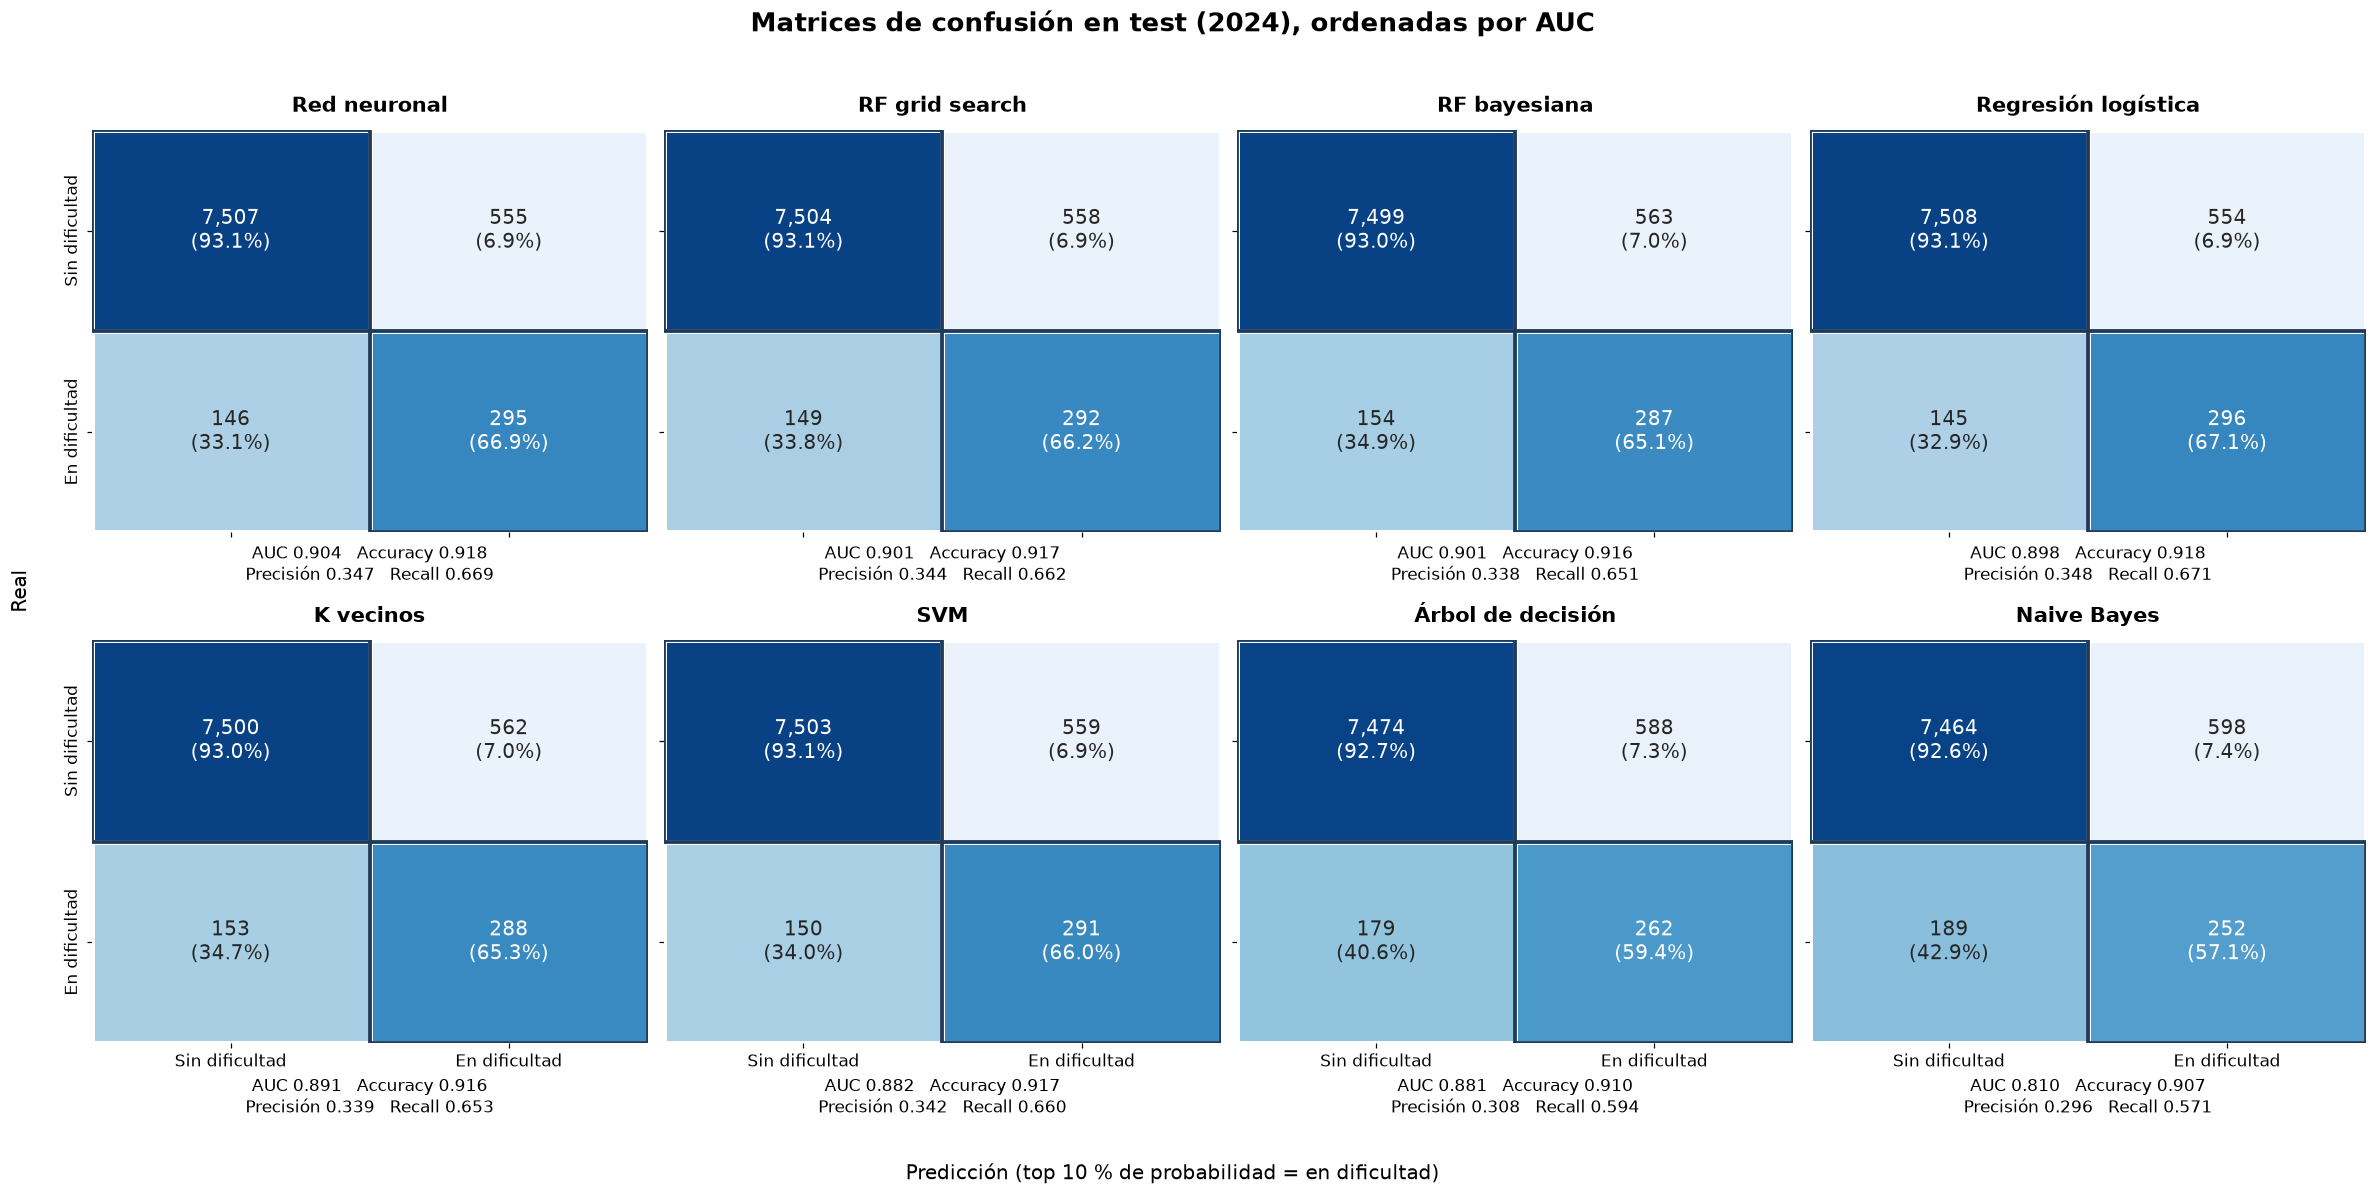

In [20]:
class_names = ["Sin dificultad", "En dificultad"]
fig, axes = plt.subplots(2, 4, figsize=(22, 11), sharex=True, sharey=True)

# Modelos ordenados de mayor a menor AUC, con sus métricas debajo de la matriz
for ax, (name, metrics) in zip(axes.ravel(), results.iterrows()):
    counts = confusion_matrix(y_test, modelado.flag_at_risk(prob_test[name]))
    estilo.confusion_heatmap(ax, counts, class_names)
    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.set_xlabel(
        f"AUC {metrics['AUC']:.3f}   Accuracy {metrics['Accuracy']:.3f}\n"
        f"Precisión {metrics['Precisión']:.3f}   Recall {metrics['Recall']:.3f}",
        fontsize=11,
    )
    ax.set_ylabel("")
    ax.tick_params(axis="x", labelsize=11)
    ax.tick_params(axis="y", labelsize=11, rotation=90)

# Ocultar los recuadros sobrantes si hay menos modelos que espacios
for ax in axes.ravel()[len(results):]:
    ax.axis("off")

fig.supxlabel("Predicción (top 10 % de probabilidad = en dificultad)", fontsize=13)
fig.supylabel("Real", fontsize=13)
fig.suptitle("Matrices de confusión en test (2024), ordenadas por AUC", fontsize=17, fontweight="bold")
plt.tight_layout(rect=[0.02, 0.02, 1, 0.96])
estilo.save_figure(fig, "fig06_matrices_confusion_test.png")
plt.show()

## 9. Conclusiones técnicas

Las conclusiones de negocio están en `README.md`.

1. **AUC-ROC como métrica.** Solo ~5 % de las empresas cae en dificultad, así que la exactitud engaña. SMOTE se aplicó solo al entrenamiento.
2. **La red neuronal lidera, con Random Forest casi empatado:** AUC 0.904, exactitud 0.918, recall 0.669 (optimizador ganador: SGD con momentum). Los dos Random Forest quedan en 0.901 y la regresión logística en 0.898.
3. **Naive Bayes es el más débil (AUC 0.810):** su supuesto de independencia choca con variables muy correlacionadas (activos–pasivos 0.86).
4. **La optimización ayudó poco:** los cuatro mejores modelos están a 0.006 de AUC entre sí. La señal viene sobre todo de los ratios y de las transformaciones, y el ajuste fino aporta el último tramo.